# LLM zero-shot (spam w klasie pozytywnej)

Wariant `spam_1`: model ocenia, czy wiadomość jest niechciana (phishing, BEC, oszustwo, spam), bez żadnych przykładów.

- **Dane:** mini zbiór testowy z `mini_test_set.ipynb` (po 300 wiadomości na źródło ID z testu podziału 42 i źródło OOD,
  całe NEBULON i KD). Zbiór jest zbalansowany, więc precision i AUCPR nie są porównywalne z pełnym testem.
- **Modele:** lokalne modele przez Ollama, kwantyzacja 4-bitowa, temperatura 0. Tryb rozumowania wyłączony
  (`think=False`), poza gpt-oss, w którym ustawiono najniższy poziom (`low`).
- **Prompt:** definicja wiadomości niechcianej i pożądanej w `llm_utils.SYSTEM_PROMPT_SPAM_1`. Tekst wiadomości jest obcinany
  do 4000 znaków. Odpowiedź to jedno słowo: UNWANTED albo LEGITIMATE.
- **Wynik i próg:** wynik ciągły to p(UNWANTED) / (p(UNWANTED) + p(LEGITIMATE)) z rozkładu pierwszego tokenu odpowiedzi.
  Decyzja to wynik >= 0.5, czyli odpowiedź bardziej prawdopodobna dla modelu. Progu przy FPR 1% nie dobierano, bo LLM nie ma
  zbioru walidacyjnego w tym ustawieniu.
- **Wznawianie:** predykcje są zapisywane co 50 wiadomości, a ponowne uruchomienie pomija wiadomości już ocenione.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import ID_SOURCES, OOD_SOURCES, corpus_metrics, load_corpora, plot_confusion_matrices, plot_curves
from llm_utils import SYSTEM_PROMPT_SPAM_1, build_messages, classify

EXPERIMENT = "llm_zero_shot_spam_1"
LABEL = "label_spam_1"
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

# model: ustawienie trybu rozumowania
MODELS = {"qwen2.5:7b": None, "qwen3.5:9b": False, "gemma4:12b": False, "gpt-oss:20b": "low"}
THRESHOLD = 0.5
SAVE_EVERY = 50
SEED = 42

mini = pd.read_parquet(ROOT / "data" / "mini_test.parquet")
print(mini.groupby("korpus").size().to_dict())

{'ID': 1500, 'OOD': 805}


In [2]:
examples = ()

## Klasyfikacja

Każdy model ocenia wszystkie wiadomości mini zbioru. Wyniki trafiają do `predictions_<model>.csv`.

In [3]:
def model_file(model):
    return TABLES / f"predictions_{model.replace(':', '_')}.csv"


import requests

available = {item["name"] for item in requests.get("http://localhost:11434/api/tags", timeout=30).json()["models"]}
for model, think in MODELS.items():
    if model not in available:
        print(f"{model}: brak modelu w Ollama, pominięty", flush=True)
        continue
    path = model_file(model)
    done = pd.read_csv(path) if path.exists() else pd.DataFrame()
    todo = mini[~mini.id.isin(set(done.get("id", [])))]
    print(f"{model}: zapisane {len(done)}, do oceny {len(todo)}", flush=True)
    rows, start = [], time.perf_counter()
    for position, row in enumerate(todo.itertuples(), 1):
        result = classify(model, build_messages(SYSTEM_PROMPT_SPAM_1, row.text, examples), think=think)
        rows.append({"id": row.id, **result})
        if position % SAVE_EVERY == 0 or position == len(todo):
            done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
            done.to_csv(path, index=False)
            rows = []
            elapsed = time.perf_counter() - start
            print(f"  {position}/{len(todo)}, {elapsed / position:.2f} s/wiadomość", flush=True)

qwen2.5:7b: zapisane 2305, do oceny 0


qwen3.5:9b: zapisane 0, do oceny 2305


  50/2305, 0.79 s/wiadomość


  100/2305, 0.62 s/wiadomość


  150/2305, 0.55 s/wiadomość


  200/2305, 0.50 s/wiadomość


... (88 outputs left out)

  2200/2305, 1.76 s/wiadomość


  2250/2305, 1.75 s/wiadomość


  2300/2305, 1.74 s/wiadomość


  2305/2305, 1.74 s/wiadomość


## Metryki dla ID i OOD

Tabela zawiera wszystkie modele. `nieprawidłowe` to liczba odpowiedzi innych niż UNWANTED lub LEGITIMATE (wynik dla nich
pochodzi z rozkładu tokenów).

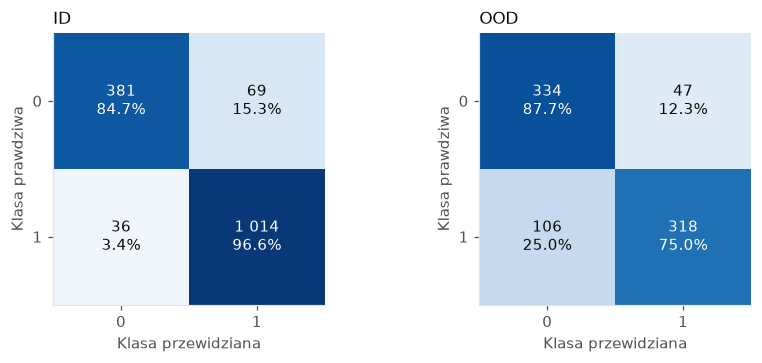

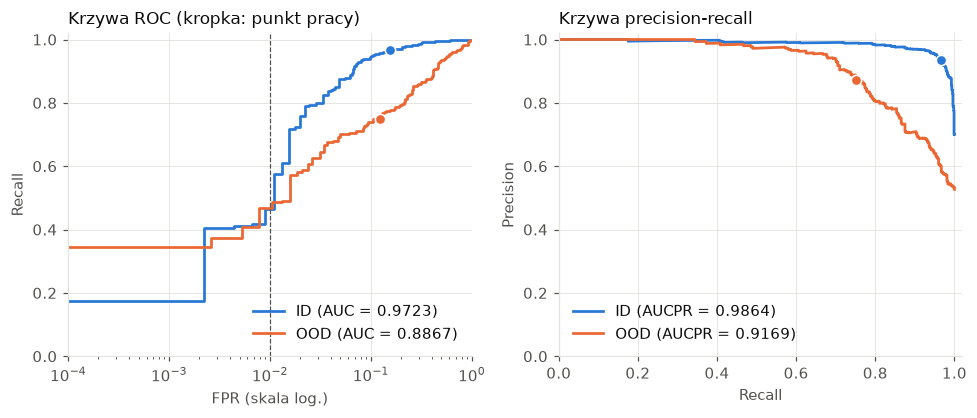

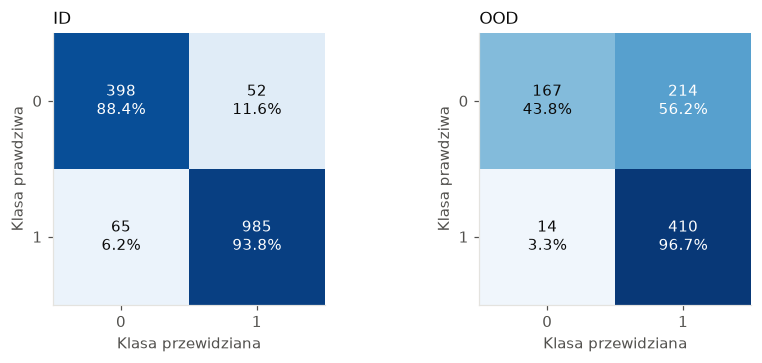

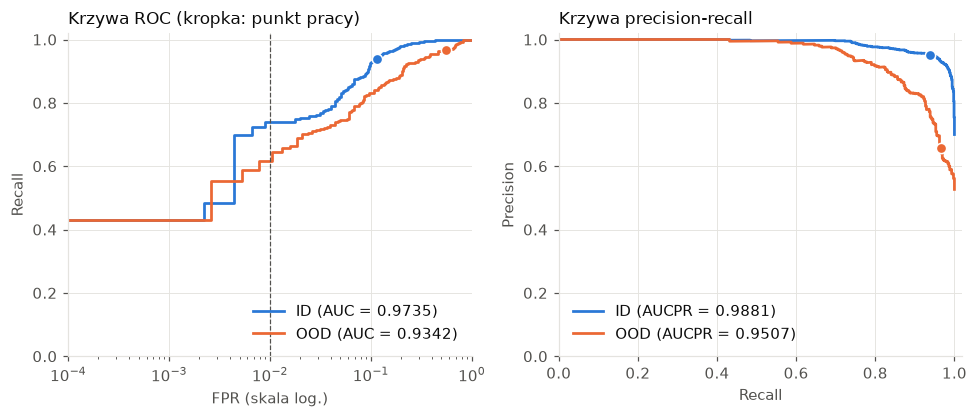

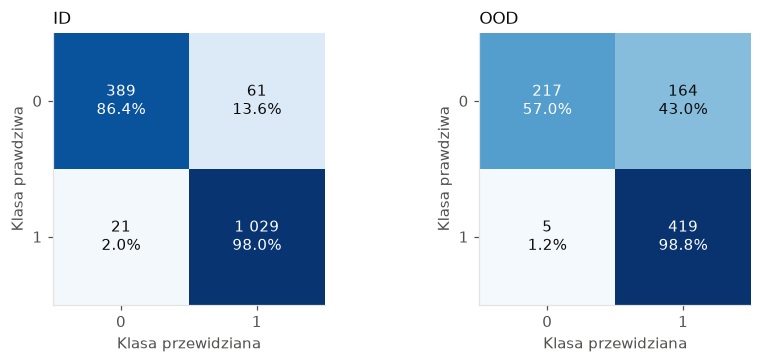

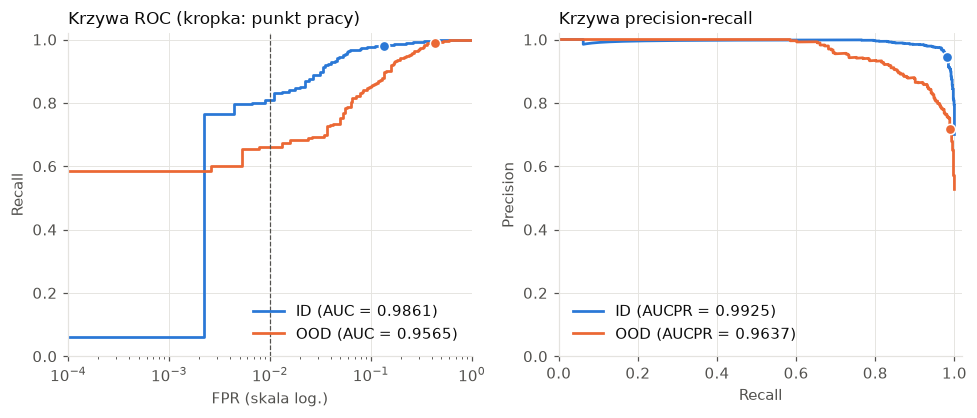

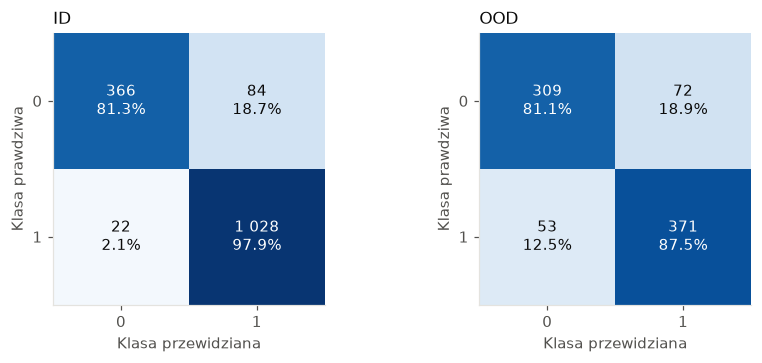

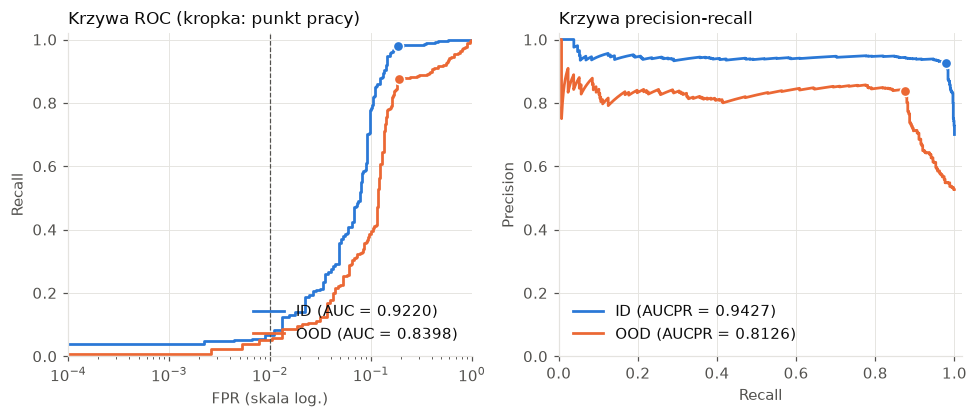

,model,n,nieprawidłowe,s_na_wiadomość,czas_min,tokeny_promptu_śr,znaki_rozumowania_śr
0,qwen2.5:7b,2305,0,0.1884,7.2367,660.7319,0.0000
1,qwen3.5:9b,2305,0,0.4021,15.4457,676.9302,0.0000
2,gemma4:12b,2305,0,1.0378,39.8675,677.4933,0.0000
3,gpt-oss:20b,2305,0,1.7373,66.7413,704.9202,85.8304


n  positives  accuracy  recall     f1  precision  roc_auc  aucpr    fpr
model       korpus                                                                                
qwen2.5:7b  ID     1500.0000  1050.0000    0.9300  0.9657 0.9508     0.9363   0.9723 0.9864 0.1533
            OOD     805.0000   424.0000    0.8099  0.7500 0.8061     0.8712   0.8867 0.9169 0.1234
qwen3.5:9b  ID     1500.0000  1050.0000    0.9220  0.9381 0.9439     0.9499   0.9735 0.9881 0.1156
            OOD     805.0000   424.0000    0.7168  0.9670 0.7824     0.6571   0.9342 0.9507 0.5617
gemma4:12b  ID     1500.0000  1050.0000    0.9453  0.9800 0.9617     0.9440   0.9861 0.9925 0.1356
            OOD     805.0000   424.0000    0.7901  0.9882 0.8322     0.7187   0.9565 0.9637 0.4304
gpt-oss:20b ID     1500.0000  1050.0000    0.9293  0.9790 0.9510     0.9245   0.9220 0.9427 0.1867
            OOD     805.0000   424.0000    0.8447  0.8750 0.8558     0.8375   0.8398 0.8126 0.1890

In [4]:
predictions = {
    model: mini.merge(pd.read_csv(model_file(model)), on="id", how="inner", validate="one_to_one") for model in MODELS
    if model_file(model).exists()
}
summary_rows, metric_tables, source_tables = [], [], []
for model, frame in predictions.items():
    id_frame, ood_frame = frame[frame.korpus == "ID"], frame[frame.korpus == "OOD"]
    corpus_sets = {"ID": (id_frame[LABEL], id_frame.score.to_numpy()), "OOD": (ood_frame[LABEL], ood_frame.score.to_numpy())}
    metric_tables.append(corpus_metrics(corpus_sets, THRESHOLD).assign(model=model))
    source_sets = {
        name: (frame.loc[frame.source == name, LABEL], frame.loc[frame.source == name, "score"].to_numpy())
        for name in ID_SOURCES + OOD_SOURCES
    }
    source_tables.append(corpus_metrics(source_sets, THRESHOLD).assign(model=model))
    summary_rows.append({
        "model": model, "n": len(frame), "nieprawidłowe": int((~frame.valid).sum()),
        "s_na_wiadomość": frame.seconds.mean(), "czas_min": frame.seconds.sum() / 60,
        "tokeny_promptu_śr": frame.prompt_tokens.mean(), "znaki_rozumowania_śr": frame.thinking_chars.mean(),
    })
    matrices = plot_confusion_matrices(corpus_sets, THRESHOLD, FIGURES / f"confusion_matrices_{model.replace(':', '_')}.pdf")
    for name, matrix in matrices.items():
        matrix.to_csv(TABLES / f"confusion_matrix_{name.lower()}_{model.replace(':', '_')}.csv")
    plot_curves(corpus_sets, THRESHOLD, FIGURES / f"roc_pr_curves_{model.replace(':', '_')}.pdf")

summary = pd.DataFrame(summary_rows)
summary.to_csv(TABLES / "summary.csv", index=False)
metrics = pd.concat(metric_tables).rename_axis("korpus").reset_index().set_index(["model", "korpus"])
metrics.to_csv(TABLES / "metrics.csv")
metrics_by_source = pd.concat(source_tables).rename_axis("source").reset_index().set_index(["model", "source"])
metrics_by_source.to_csv(TABLES / "metrics_by_source.csv")
display(summary)
display(metrics)

## Metryki według źródła

Puste wartości oznaczają metrykę, której nie da się policzyć dla jednej klasy, np. FPR dla Nazario.

In [5]:
display(metrics_by_source)

n  positives  accuracy  recall     f1  precision  roc_auc  aucpr    fpr
model       source                                                                                 
qwen2.5:7b  nazario  300.0000   300.0000    0.9167  0.9167 0.9565     1.0000      NaN    NaN    NaN
            nigerian 300.0000   300.0000    1.0000  1.0000 1.0000     1.0000      NaN    NaN    NaN
            trec05   300.0000   150.0000    0.8367  0.9533 0.8537     0.7730   0.9465 0.9362 0.2800
            trec06   300.0000   150.0000    0.9400  0.9867 0.9427     0.9024   0.9737 0.9696 0.1067
            trec07   300.0000   150.0000    0.9567  0.9867 0.9579     0.9308   0.9834 0.9778 0.0733
            ferb     300.0000   150.0000    0.6867  0.4533 0.5913     0.8500   0.7422 0.8004 0.0800
            kd10000   60.0000    55.0000    1.0000  1.0000 1.0000     1.0000   1.0000 1.0000 0.0000
            nebulon  145.0000    69.0000    0.7724  0.6667 0.7360     0.8214   0.8707 0.8824 0.1316
            zeroday  300.0000   150.0000    0.9133  0.9933 0.9198     0.8563   0.9886 0.9878 0.1667
qwen3.5:9b  nazario  300.0000   300.0000    0.8900  0.8900 0.9418     1.0000      NaN    NaN    NaN
            nigerian 300.0000   300.0000    0.9933  0.9933 0.9967     1.0000      NaN    NaN    NaN
            trec05   300.0000   150.0000    0.8767  0.9533 0.8854     0.8266   0.9376 0.9367 0.2000
            trec06   300.0000   150.0000    0.9200  0.9133 0.9195     0.9257   0.9763 0.9693 0.0733
            trec07   300.0000   150.0000    0.9300  0.9333 0.9302     0.9272   0.9860 0.9857 0.0733
            ferb     300.0000   150.0000    0.5633  0.9933 0.6946     0.5341   0.9150 0.9270 0.8667
            kd10000   60.0000    55.0000    1.0000  1.0000 1.0000     1.0000   1.0000 1.0000 0.0000
            nebulon  145.0000    69.0000    0.8138  0.8116 0.8058     0.8000   0.8717 0.8726 0.1842
            zeroday  300.0000   150.0000    0.7667  1.0000 0.8108     0.6818   0.9959 0.9961 0.4667
gemma4:12b  nazario  300.0000   300.0000    0.9633  0.9633 0.9813     1.0000      NaN    NaN    NaN
            nigerian 300.0000   300.0000    1.0000  1.0000 1.0000     1.0000      NaN    NaN    NaN
            trec05   300.0000   150.0000    0.8733  0.9533 0.8827     0.8218   0.9710 0.9746 0.2067
            trec06   300.0000   150.0000    0.9433  0.9933 0.9460     0.9030   0.9866 0.9720 0.1067
            trec07   300.0000   150.0000    0.9467  0.9867 0.9487     0.9136   0.9932 0.9933 0.0933
            ferb     300.0000   150.0000    0.7600  1.0000 0.8065     0.6757   0.9462 0.9447 0.4800
            kd10000   60.0000    55.0000    1.0000  1.0000 1.0000     1.0000   1.0000 1.0000 0.0000
            nebulon  145.0000    69.0000    0.8000  0.9275 0.8153     0.7273   0.9428 0.9487 0.3158
            zeroday  300.0000   150.0000    0.7733  1.0000 0.8152     0.6881   0.9972 0.9976 0.4533
gpt-oss:20b nazario  300.0000   300.0000    0.9467  0.9467 0.9726     1.0000      NaN    NaN    NaN
            nigerian 300.0000   300.0000    0.9967  0.9967 0.9983     1.0000      NaN    NaN    NaN
            trec05   300.0000   150.0000    0.8633  0.9933 0.8791     0.7884   0.8869 0.8308 0.2667
            trec06   300.0000   150.0000    0.9233  0.9933 0.9283     0.8713   0.9561 0.9454 0.1467
            trec07   300.0000   150.0000    0.9167  0.9800 0.9216     0.8698   0.9445 0.9192 0.1467
            ferb     300.0000   150.0000    0.8367  0.7267 0.8165     0.9316   0.8332 0.8557 0.0533
            kd10000   60.0000    55.0000    1.0000  1.0000 1.0000     1.0000   1.0000 1.0000 0.0000
            nebulon  145.0000    69.0000    0.8483  0.8261 0.8382     0.8507   0.8434 0.8096 0.1316
            zeroday  300.0000   150.0000    0.8200  1.0000 0.8475     0.7353   0.7929 0.7059 0.3600